# A first Fe-Cr-Ni moving-boundary simulation

How does a BCC layer grow into FCC when chromium and nickel diffuse across their
interface? We will sample thermodynamic data, build a model, simulate one hour,
and plot the result. Each step uses the installed `moving_boundary` package directly.

This is a planar, isothermal, closed diffusion couple with local equilibrium at
the interface, equal constant molar volumes, and no Kirkendall flow. The temperature,
compositions, and dimensions follow couple B in [1, 2], using the bundled open
database [3, 4]. These short-run settings demonstrate the workflow; they are not
a convergence study or a reproduction of measured profiles.

**Run from top to bottom** with the package installed in your `kawin` environment.
The kernel can start in this notebook's directory (`packages/moving-boundary/examples`)
or at the **extraction repository root** (the directory containing `packages/`).
The database setup below handles both without changing the working directory.
If you copy the notebook elsewhere, set `database` to your TDB path.
No Thermo-Calc installation is needed.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt

from moving_boundary.mesh import CartesianFD1D, ProfileBuilder, StepProfile1D
from moving_boundary.mesh.TransformedGrids import two_phase_landau_grids
from moving_boundary.plotting import plot_composition_profiles, plot_interface_history
from moving_boundary.providers.pycalphad import create_pycalphad_thermodynamics_source
from moving_boundary.sampling import ternary_simplex_points
from moving_boundary.solvers import MovingBoundaryIllingworthTernaryFD1DModel
from moving_boundary.surrogates import TernaryMovingBoundaryThermodynamicsSurrogate

## 1. Define the physical problem

Phases are ordered **left to right**: BCC_A2, then FCC_A1. Iron is the dependent
component, so every composition pair below means **[chromium, nickel] mole fractions**.
Lengths are in metres, temperature in kelvin, and time in seconds.

We model half of a symmetric FCC/BCC/FCC couple: half the 124.1 micrometre BCC
layer, followed by 2000 micrometres of FCC [2, Table 3]. Both outer boundaries
have zero flux. The tiny interface offset avoids starting exactly on a physical
mesh node; it does not represent an additional physical layer.

In [2]:
database = Path("FeCrNi_MatCalc_open.tdb")  # kernel starts beside this notebook
if not database.is_file():
    database = Path("packages/moving-boundary/examples") / database  # repository root

elements = ["FE", "CR", "NI"]
independent = ["CR", "NI"]
phases = ["BCC_A2", "FCC_A1"]
temperature = 1373.0
left_composition = [0.39696, 0.0001]   # BCC far field [2, Table 3]
right_composition = [0.139297, 0.142387]  # FCC far field [2, Table 3]

domain_length = 2000.0e-6 + 124.1e-6 / 2.0
interface_position = domain_length - 2000.0e-6 + 1.0e-12
duration = 3600.0

## 2. Sample thermodynamics and diffusivities

First create a pycalphad source, restricting equilibrium to our two phases.
The bundled database is an adapted excerpt of the MatCalc open steel databases
[3, 4]; its attribution and licence are in [the examples README](README.md#open-fe-cr-ni-database-and-surrogate-workflow).
It differs from the database used in the original research.

In [3]:
source = create_pycalphad_thermodynamics_source(
    database, elements, phases, use_default_phases=False, g_offset=0.0,
)

The solver needs both interface equilibrium compositions and diffusivity matrices.
A surrogate supplies these from sampled data, avoiding database calculations at
every time step. The probe point is inside this database's two-phase region at
1373 K; it seeds the tie-line family rather than setting the initial bulk profile.

Here we request 17 tie lines and a bulk composition grid with spacing 0.05.
Unusable bulk samples are omitted. The `"raise"` validity policy rejects queries
outside the surrogate's permitted domain. Sampling runs afresh when you rerun
this cell; saving and reloading are covered by the full workflow linked below.

In [ ]:
#NOTES Remind me that I should probably cleanup the output print statements that occur when the tieline sweep runs
bulk_points = ternary_simplex_points(spacing=0.05)
surrogate = TernaryMovingBoundaryThermodynamicsSurrogate.from_database(
    thermodynamics=source,
    elements=elements,
    phases=phases,
    tieline_phases=phases,
    temperature=temperature,
    probe_point=[0.45, 0.21],
    probe_samples_per_side=8,
    precipitate_phase=phases[1],
    diffusivity_bulk_points=bulk_points,
    diffusivity_interpolation="simplex_positive_2x2",
    skip_failed_bulk_calculations=True,
    drop_invalid_bulk_matrices=True,
    validity_policy="raise",
    min_composition=1.0e-10,
)

for phase in phases:
    compositions, matrices = surrogate.get_diffusivity_samples(phase)
    print(f"{phase}: {len(compositions)} retained bulk diffusivity samples")

Initial scan direction: [0.59321673 0.8050428 ]
Initial seed_sample: {'probe': array([0.45, 0.21]), 'endpoints': (array([0.57577713, 0.11731785]), array([0.35589239, 0.27934564])), 'diffusivities': (array([[1.51312606e-13, 1.69738852e-13],
       [3.93063828e-14, 9.29449039e-14]]), array([[ 3.83127736e-15, -1.42282854e-15],
       [-9.43938713e-16,  4.74858267e-15]])), 'midpoint': array([0.46583476, 0.19833174])}
totalNumCalcs: -1


i+1: 32
j: 14
scan direction after neg scan: [0.59321673 0.8050428 ]
seed_sample after neg scan: {'probe': array([0.45, 0.21]), 'endpoints': (array([0.57577713, 0.11731785]), array([0.35589239, 0.27934564])), 'diffusivities': (array([[1.51312606e-13, 1.69738852e-13],
       [3.93063828e-14, 9.29449039e-14]]), array([[ 3.83127736e-15, -1.42282854e-15],
       [-9.43938713e-16,  4.74858267e-15]])), 'midpoint': array([0.46583476, 0.19833174])}
totalNumCalcs: -1


i+1: 24
j: 14
scan direction after pos scan: [0.59321673 0.8050428 ]
seed_sample after pos scan: {

Resampling tieline data: 100%|██████████| 17/17 [00:00<00:00, 56.52it/s]


totalNumCalcs: -1


Sampling bulk diffusivity for phase FCC_A1: 100%|██████████| 231/231 [00:01<00:00, 191.40it/s]


BCC_A2: 248 retained bulk diffusivity samples
FCC_A1: 248 retained bulk diffusivity samples


## 3. Build the mesh and model

The physical mesh defines the initial step profile over the whole couple.
The solver evolves concentrations on two additional, transformed grids, one per
phase. Those grids follow the moving interface and concentrate nodes near it.
Their 21 and 41 nodes control the phase solves; the physical mesh's 61 nodes
are a separate representation.

In [8]:
mesh = CartesianFD1D(independent, [0.0, domain_length], 61)
profile = ProfileBuilder([
    (StepProfile1D(interface_position, left_composition, right_composition), independent)
])
mesh.setResponseProfile(profile)

left_grid, right_grid = two_phase_landau_grids(
    21, 41, method="linear", spacing_ratio=0.1,
)

The same surrogate supplies bulk diffusivities and the interface tie-line family.
In **lagged** mode, composition-dependent bulk matrices are updated from the
accepted profile and held fixed during each candidate step. The initial interface
tie line is selected by balancing the two components' interface fluxes.

Semi-logarithmic steps resolve the short initial transient before increasing in
size. `terminal_thin_phase_policy="raise"` stops with an error if a phase becomes
too thin to continue. Recording retains the initial and subsequent profiles for plotting.

In [ ]:
model = MovingBoundaryIllingworthTernaryFD1DModel(
    mesh=mesh,
    elements=elements,
    phases=phases,
    thermodynamics=surrogate,
    temperature=temperature,
    interfacePosition=interface_position,
    interface_equilibrium=surrogate,
    initial_eta_method="instantaneous_balance",
    initial_eta_bracket=(1.0e-3, 1.0 - 1.0e-3),
    initial_eta_guess=0.5,
    bulk_diffusivity_mode="composition_dependent_lagged",
    transformed_u_grid=left_grid,
    transformed_v_grid=right_grid,
    time_step=1.0, # This only matters if dt_mode is "fixed", ignored for dt_mode="semi_log"
    dt_mode="semi_log",
    semiLog_dt=0.05,
    semiLogT0=1.0e-6,
    tolerance=1.0e-12,
    terminal_thin_phase_width=1.0e-7,
    terminal_thin_phase_policy="raise",
    record=True,
)

## 4. Simulate one hour

`solve` advances the model by the requested duration. To repeat from the original
initial condition, rerun the mesh and model cells before running this cell again.

In [10]:
model.solve(duration, minDtFrac=1.0e-14, verbose=True)

print(f"Simulated time: {model.currentTime / 3600.0:.2f} h")
print(f"Interface position: {float(model.getInterfacePosition()) * 1.0e6:.2f} micrometres")

Iteration	Sim Time (h)	Run time (s)
0		0.000e+00		0.0
10		4.356e-10		0.0
20		7.183e-10		0.1
30		1.184e-09		0.1
40		1.952e-09		0.2
50		3.219e-09		0.2
60		5.307e-09		0.3
70		8.750e-09		0.3
80		1.443e-08		0.3
90		2.379e-08		0.4
100		3.922e-08		0.4
110		6.466e-08		0.5
120		1.066e-07		0.5
130		1.758e-07		0.5
140		2.898e-07		0.6
150		4.777e-07		0.6
160		7.877e-07		0.7
170		1.299e-06		0.7
180		2.141e-06		0.7
190		3.530e-06		0.8
200		5.820e-06		0.8
210		9.596e-06		0.9
220		1.582e-05		0.9
230		2.608e-05		0.9
240		4.300e-05		1.0
250		7.090e-05		1.0
260		1.169e-04		1.0
270		1.927e-04		1.1
280		3.178e-04		1.1
290		5.239e-04		1.1
300		8.638e-04		1.2
310		1.424e-03		1.2
320		2.348e-03		1.3
330		3.871e-03		1.3
340		6.382e-03		1.4
350		1.052e-02		1.4
360		1.735e-02		1.5
370		2.860e-02		1.5
380		4.716e-02		1.6
390		7.775e-02		1.6
400		1.282e-01		1.7
410		2.114e-01		1.7
420		3.485e-01		1.8
430		5.745e-01		1.8
440		9.472e-01		1.9
442		1.000e+00		1.9
Simulated time: 1.00 h
Interface position: 72.05 microm

## 5. Inspect the result

Compare the initial and final mole-fraction profiles. The plots zoom into the
first 200 micrometres to show the interface region; the full model domain is
about 2062 micrometres long. Each phase is plotted separately so the interface
composition jump remains visible. Remove `xlim` to see the whole couple.

The plotted initial state already imposes local equilibrium at the interface endpoints.

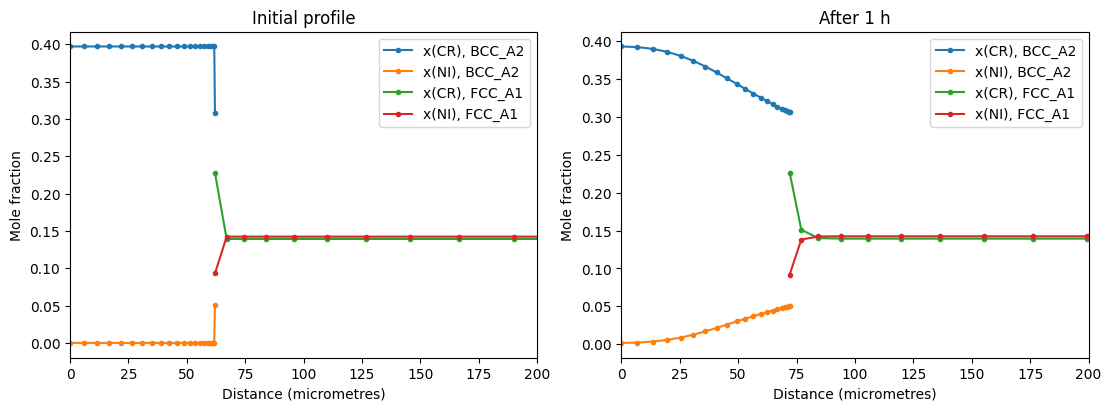

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
plot_composition_profiles(model, time=0.0, position_scale=1.0e6, ax=axes[0], marker='o', markersize=3)
plot_composition_profiles(model, position_scale=1.0e6, ax=axes[1], marker='o', markersize=3)
axes[0].set_title("Initial profile")
axes[1].set_title(f"After {model.currentTime / 3600.0:g} h")
for ax in axes:
    ax.set(xlim=(0, 200), xlabel="Distance (micrometres)", ylabel="Mole fraction")
    ax.legend()
plt.show()

The interface history shows whether the BCC layer grows or shrinks. Its position
is measured from the left symmetry plane, so it is also the BCC half-layer thickness.

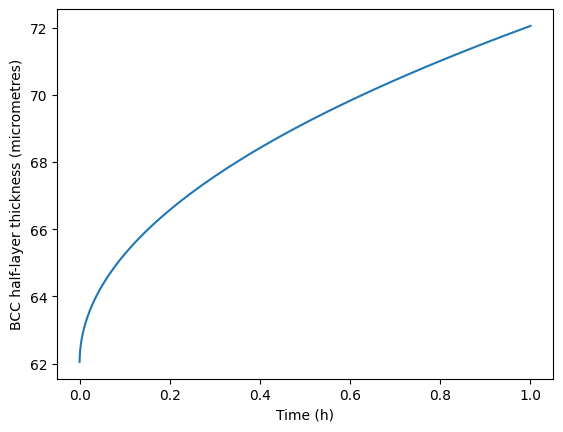

In [16]:
ax = plot_interface_history(model, time_scale=1.0 / 3600.0, position_scale=1.0e6)
ax.set(xlabel="Time (h)", ylabel="BCC half-layer thickness (micrometres)")
plt.show()

## Optional: check conservation

With zero-flux outer boundaries, each component's total inventory should remain
constant. This reports the largest component-relative drift over the recorded
history, including intermediate excursions. While small drift checks conservation,
it does not establish profile accuracy or surrogate quality.

In [19]:
from moving_boundary.analytic import recorded_history
from moving_boundary.run_diagnostics import inventory_drift

_, inventories = recorded_history(model.inventoryData)
absolute_drift, relative_drift = inventory_drift(inventories)
print(f"Maximum relative inventory drift: {relative_drift:.2e}")

Maximum relative inventory drift: 2.20e-11


## Things to try next

- Change `duration`, rebuild the model, and compare the interface history.
- Increase the transformed grid counts or reduce `semiLog_dt`, then compare the
  final profiles. These are starting points for a numerical convergence study.
- Reduce the bulk sampling spacing to 0.025 or increase the tie-line samples,
  then rerun sampling and all following cells to investigate sampling sensitivity.

For saving/reloading, sample diagnostics, and optional backend comparisons, see
[the full Fe-Cr-Ni workflow](surrogate_workflow_fecrni_open.py) and
[the reusable workflow guide](../docs/example-workflows.md).

## References

1. M. Kajihara, C.-B. Lim, M. Kikuchi, "Experimental study on dissolution of alpha
   phase in gamma/alpha/gamma diffusion couples of the Fe-Cr-Ni system,"
   *ISIJ International* 33 (1993) 498-507. Source of the couples and annealing temperature.
2. B.-J. Lee, K. H. Oh, "Numerical treatment of the moving interface in diffusional
   reactions," *Z. Metallkd.* 87 (1996) 195-204. Couple B compositions and dimensions
   from Table 3, originating in [1].
3. E. Povoden-Karadeniz, MatCalc thermodynamic steel database mc_fe, release 2.060,
   TU Wien, [MatCalc open databases](https://www.matcalc.at/index.php/databases/open-databases).
   Thermodynamic parameters in the bundled adapted excerpt; ODbL 1.0 / DbCL 1.0.
4. E. Povoden-Karadeniz, MatCalc diffusion mobility database for steel (mc_fe), TU Wien,
   same source and licence as [3]. Mobility parameters in the excerpt match releases
   2.012, 2.015, and 2.016; no single release is identified.